# Assignment 1: Data Profiling (EDA) Report

**Progress: Tasks A, B, C and D assembled.**

| Member | Matric number | Contribution |
|---|---|---|
| AFIQ AMALI | A212655 | A: Scenario and data source |
| TAN ZU BIN | A209895 | B: Missing values and other quality issues |
| HANA NADIA | A211277 | C: Outliers and diagnostic charts |
| SYAFIQAH FARZANA | A211275 | D: PII, bias and conclusion |

## 1. Scenario

An online fashion retailer wants to investigate which customer demographic segments and product categories contribute to the highest product return rates. The dataset contains customer demographic information, product categories, and transaction records that distinguish between sales and returns, allowing return behaviour to be compared across different customer and product groups. The findings could help the retailer improve inventory planning and reduce costs associated with processing returned products.

## 2. Data Source and Run Instructions

The dataset used for this analysis is the **Global Fashion Retail Stores Dataset** by Ric Gomes, obtained from [Kaggle](https://www.kaggle.com/datasets/ricgomes/global-fashion-retail-stores-dataset)

- customers.csv — customer demographic information
- products.csv — product and category information
- transactions.csv — sales and return transaction information

In [176]:
%pip install -U kagglehub pandas matplotlib

In [177]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
dataset = "ricgomes/global-fashion-retail-stores-dataset/versions/24"

for filename in ["customers.csv", "products.csv", "transactions.csv"]:
    if not (data_dir / filename).exists():
        kagglehub.dataset_download(dataset, path=filename, output_dir=str(data_dir))
    print(f"Ready: {filename}")

Ready: customers.csv
Ready: products.csv
Ready: transactions.csv


In [178]:
import pandas as pd

customers = pd.read_csv(
    "data/customers.csv",
    dtype={"Telephone": "string"},
    low_memory=False,
)

products = pd.read_csv(
    "data/products.csv",
    low_memory=False,
)

print(f"Customers: {customers.shape[0]:,} rows, "
      f"{customers.shape[1]} columns")

print(f"Products: {products.shape[0]:,} rows, "
      f"{products.shape[1]} columns")

Customers: 1,643,306 rows, 9 columns
Products: 17,940 rows, 12 columns


In [179]:
#load data
customers = pd.read_csv("data/customers.csv")
products = pd.read_csv("data/products.csv")

transactions_preview = pd.read_csv(
    "data/transactions.csv",
    nrows=1000
)

/tmp/ipykernel_1249/479188055.py:2: DtypeWarning: Columns (3: Telephone) have mixed types. Specify dtype option on import or set low_memory=False.
  customers = pd.read_csv("data/customers.csv")


In [180]:
customers.head()

,Customer ID,Name,Email,Telephone,City,Country,Gender,Date Of Birth,Job Title
0,1,Tyler Garcia,tyler.garcia@fake_gmail.com,922.970.2265x47563,New York,United States,M,2003-07-15,NaN
1,2,Joshua Miller,joshua.miller@fake_gmail.com,+1-958-729-6169,New York,United States,M,2000-06-16,Records manager
2,3,Alison Marshall DDS,alison.marshall.dds@fake_hotmail.com,+1-645-567-0876x5409,New York,United States,F,2003-07-22,NaN
3,4,Jeffery Acosta,jeffery.acosta@fake_yahoo.com,212.336.0912x84994,New York,United States,M,1996-11-12,Proofreader
4,5,Ashley Sanders,ashley.sanders@fake_hotmail.com,7814535781,New York,United States,F,1998-02-10,Exercise physiologist


In [181]:
products.head()

,Product ID,Category,Sub Category,Description PT,Description DE,Description FR,Description ES,Description EN,Description ZH,Color,Sizes,Production Cost
0,1,Feminine,Coats and Blazers,Esportivo Veludo Verde Com Botões,Sport Samt Sport Mit Knöpfen,Sports Velvet Sports Avec Des Boutons,Deportes De Terciopelo Con Botones,Sports Velvet Sports With Buttons,运动天鹅绒运动与按钮,NaN,S|M|L|XL,10.73
1,2,Feminine,Sweaters and Knitwear,Luxuoso Denim Rosa Com Botões,Luxuriöser Rosa Jeans Mit Knöpfen,Léchard De Denim Rose Avec Boutons,Denim Rosa Lujoso Con Botones,Luxurious Pink Denim With Buttons,豪华的粉红色牛仔布和纽扣,PINK,S|M|L|XL,19.55
2,3,Feminine,Dresses and Jumpsuits,Retrô Tricot Preto Estampado,Black Tricot Gedruckter Tricot,Tricot Imprimé En Tricot Noir,Tricot Negro Tricot Impreso,Black Tricot Printed Tricot,黑色三角形印刷三角形,BLACK,S|M|L|XL,25.59
3,4,Feminine,Shirts and Blouses,Blusa De Algodão Básica,Basis -Baumwollbluse,Chemisier En Coton De Base,Blusa De Algodón,Basic Cotton Blouse,基本的棉衬衫,NaN,S|M|L|XL,27.62
4,5,Feminine,T-shirts and Tops,T-Shirt Básica De Algodão,Basis-Baumwoll-T-Shirt,T-Shirt En Coton De Base,Camiseta Básica De Algodón,Basic Cotton T-Shirt,基本棉T恤,NaN,S|M|L,11.69


In [182]:
transactions.head()

,Invoice ID,Line,Customer ID,Product ID,Size,Color,Unit Price,Quantity,Date,Discount,...,Currency Symbol,SKU,Transaction Type,Payment Method,Invoice Total,Color Missing,Size Missing,Invoice Line Review,Invoice Total Outlier,Unit Price Outlier
0,INV-US-001-03558761,1,47162,485,M,NaN,80.5,1.0,2023-01-01 15:42:00,0.0,...,$,MASU485-M-,Sale,Cash,126.7,True,False,False,False,False
1,INV-US-001-03558761,2,47162,2779,G,NaN,31.5,1.0,2023-01-01 15:42:00,0.4,...,$,CHCO2779-G-,Sale,Cash,126.7,True,False,False,False,False
2,INV-US-001-03558761,3,47162,64,M,NEUTRAL,45.5,1.0,2023-01-01 15:42:00,0.4,...,$,MACO64-M-NEUTRAL,Sale,Cash,126.7,False,False,False,False,False
3,INV-US-001-03558762,1,10142,131,M,BLUE,70.0,1.0,2023-01-01 20:04:00,0.4,...,$,FECO131-M-BLUE,Sale,Cash,77.0,False,False,False,False,False
4,INV-US-001-03558762,2,10142,716,L,WHITE,26.0,1.0,2023-01-01 20:04:00,0.0,...,$,MAT-716-L-WHITE,Sale,Cash,77.0,False,False,False,False,False


In [183]:
print("Customer columns:")
print(customers.columns.tolist())

print("\nProduct columns:")
print(products.columns.tolist())

print("\nTransaction columns:")
print(transactions.columns.tolist())

Customer columns:
['Customer ID', 'Name', 'Email', 'Telephone', 'City', 'Country', 'Gender', 'Date Of Birth', 'Job Title']

Product columns:
['Product ID', 'Category', 'Sub Category', 'Description PT', 'Description DE', 'Description FR', 'Description ES', 'Description EN', 'Description ZH', 'Color', 'Sizes', 'Production Cost']

Transaction columns:
['Invoice ID', 'Line', 'Customer ID', 'Product ID', 'Size', 'Color', 'Unit Price', 'Quantity', 'Date', 'Discount', 'Line Total', 'Store ID', 'Employee ID', 'Currency', 'Currency Symbol', 'SKU', 'Transaction Type', 'Payment Method', 'Invoice Total', 'Color Missing', 'Size Missing', 'Invoice Line Review', 'Invoice Total Outlier', 'Unit Price Outlier']


In [184]:
print("Gender:")
print(customers["Gender"].value_counts(dropna=False))

print("\nProduct Category:")
print(products["Category"].value_counts(dropna=False))

print("\nTransaction Type:")
print(transactions["Transaction Type"].value_counts(dropna=False))

Gender:
Gender
M    964562
F    677041
D      1703
Name: count, dtype: int64

Product Category:
Category
Feminine     7590
Masculine    6210
Children     4140
Name: count, dtype: int64

Transaction Type:
Transaction Type
Sale      1322233
Return      73773
NaN             1
Name: count, dtype: int64


In [185]:
print("Customer rows:", len(customers))
print("Unique Customer IDs:", customers["Customer ID"].nunique())

print("Product rows:", len(products))
print("Unique Product IDs:", products["Product ID"].nunique())

Customer rows: 1643306
Unique Customer IDs: 1643306
Product rows: 17940
Unique Product IDs: 17940


In [186]:
customer_match_rate = (
    transactions["Customer ID"]
    .isin(customers["Customer ID"])
    .mean() * 100
)

product_match_rate = (
    transactions["Product ID"]
    .isin(products["Product ID"])
    .mean() * 100
)

print(f"Customer ID match rate: {customer_match_rate:.2f}%")
print(f"Product ID match rate: {product_match_rate:.2f}%")

Customer ID match rate: 100.00%
Product ID match rate: 100.00%


## 2.2 Raw Dataset Description

### customers.csv

The customers.csv dataset contains **1,643,306 rows and 9 columns**. Each row represents one customer.

The columns are:

- Customer ID — identifier used to distinguish each customer
- Name — customer name
- Email — customer email address
- Telephone — customer telephone number
- City — customer's city
- Country — customer's country
- Gender — customer's recorded gender category
- Date Of Birth — customer's date of birth
- Job Title — customer's recorded occupation or job title

For the business question, the most relevant demographic variables are Gender, Date Of Birth, City, and Country.

### products.csv

The products.csv dataset contains **17,940 rows and 12 columns**. Each row represents a product.

The columns include:

- Product ID — unique product identifier
- Category — main product category
- Sub Category — more detailed product classification
- Color — product colour
- Sizes — available product sizes
- Production Cost — cost associated with producing the product

The dataset contains three main product categories:

- Feminine — 7,590 products
- Masculine — 6,210 products
- Children — 4,140 products

Product ID will be used to connect the product information to transaction records.

### transactions.csv

The transactions.csv dataset contains transaction-level information. **6,416,827 rows and 19 columns** was initially loaded to inspect the dataset  without loading the entire large file into memory.

Each row represents a transaction line associated with a customer and a product.

Important columns include:

- Invoice ID — transaction invoice identifier
- Line — line number within an invoice
- Customer ID — identifies the customer involved in the transaction
- Product ID — identifies the product involved
- Size — size selected in the transaction
- Color — colour selected in the transaction
- Unit Price — price per unit
- Quantity — quantity involved in the transaction
- Date — date of the transaction
- Discount — discount applied
- Line Total — total for the transaction line
- Store ID — store associated with the transaction
- Employee ID — employee associated with the transaction
- Currency and Currency Symbol — transaction currency
- SKU — stock keeping unit
- Transaction Type — identifies whether the transaction is a Sale or Return
- Payment Method — method used for payment
- Invoice Total — total invoice amount

## 2.3 Dataset Integration

The three datasets are related using two identifiers.

Customer ID connects the customer dataset to the transaction dataset:

**customers.csv → Customer ID → transactions.csv**

Product ID connects the transaction dataset to the product dataset:

**transactions.csv → Product ID → products.csv**

After integration, each transaction can be associated with both the demographic characteristics of the customer and the category of the purchased or returned product. This structure will allow return rates to be compared across demographic segments such as gender, age group, country, and city, as well as across product categories and sub-categories.

## 3. Data Profiling and Issue Handling

### 3.1 Missing Values

Count missing values before cleaning. pandas missing-value detection does not by itself identify every possible placeholder or blank string.

In [187]:
def missing_summary(df):
    summary = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing (%)": (df.isna().mean() * 100).round(2),
    })

    return summary.sort_values("Missing Count", ascending=False)


customer_missing = missing_summary(customers)
product_missing = missing_summary(products)

print("CUSTOMERS")
display(customer_missing)

print("PRODUCTS")
display(product_missing)

CUSTOMERS


,Missing Count,Missing (%)
Job Title,584185,35.55
Customer ID,0,0.00
Name,0,0.00
Telephone,0,0.00
Email,0,0.00
City,0,0.00
Country,0,0.00
Gender,0,0.00
Date Of Birth,0,0.00


PRODUCTS


,Missing Count,Missing (%)
Color,12445,69.37
Sizes,2070,11.54
Product ID,0,0.00
Category,0,0.00
Description PT,0,0.00
Sub Category,0,0.00
Description DE,0,0.00
Description FR,0,0.00
Description EN,0,0.00
Description ES,0,0.00


### Customer Missing-Value Findings

Job Title is missing for 584,185 customers (35.55%).
All other customer columns have no missing values recognised
by pandas at this stage.

Proposed handling: retain these customer records and leave
unrecorded occupations as missing. Job Title is not essential
for the planned comparisons by age, gender, and product category.
Dropping these customers would unnecessarily reduce coverage.

If occupation is analysed later, missing occupations should be
reported as a separate "Not recorded" group, rather than guessed.

### Investigating Missing Product Attributes

Color is missing for 12,445 products (69.37%), while Sizes is
missing for 2,070 products (11.54%).

We examine missingness by product subcategory before deciding
how to handle these values. Missing values alone do not establish
whether an attribute is unknown or not applicable.

In [188]:
product_missing_by_group = (
    products
    .assign(
        color_missing=products["Color"].isna(),
        sizes_missing=products["Sizes"].isna(),
    )
    .groupby(["Category", "Sub Category"])
    .agg(
        product_count=("Product ID", "size"),
        color_missing_pct=("color_missing", "mean"),
        sizes_missing_pct=("sizes_missing", "mean"),
    )
)

percent_columns = ["color_missing_pct", "sizes_missing_pct"]

product_missing_by_group[percent_columns] = (
    product_missing_by_group[percent_columns] * 100
).round(2)

display(product_missing_by_group)

product_count  \
Category  Sub Category                                          
Children  Accessories                                     690   
          Baby (0-12 months)                              690   
          Coats                                           690   
          Girl and Boy (1-5 years, 6-14 years)            690   
          Pajamas                                         690   
          Sweaters                                        690   
Feminine  Accessories                                     690   
          Coats and Blazers                               690   
          Dresses and Jumpsuits                           690   
          Lingerie and Pajamas                            690   
          Pants and Jeans                                 690   
          Shirts and Blouses                              690   
          Skirts and Shorts                               690   
          Sportswear                                      690   
          Suits and Sets                                  690   
          Sweaters and Knitwear                           690   
          T-shirts and Tops                               690   
Masculine Accessories                                     690   
          Coats and Blazers                               690   
          Pants and Jeans                                 690   
          Shirts                                          690   
          Sportswear                                      690   
          Suits and Blazers                               690   
          Sweaters and Sweatshirts                        690   
          T-shirts and Polos                              690   
          Underwear and Pajamas                           690   

                                                color_missing_pct  \
Category  Sub Category                                              
Children  Accessories                                       99.28   
          Baby (0-12 months)                                13.91   
          Coats                                             13.19   
          Girl and Boy (1-5 years, 6-14 years)              16.67   
          Pajamas                                           98.84   
          Sweaters                                          98.26   
Feminine  Accessories                                       87.39   
          Coats and Blazers                                 15.36   
          Dresses and Jumpsuits                             14.78   
          Lingerie and Pajamas                             100.00   
          Pants and Jeans                                   98.99   
          Shirts and Blouses                               100.00   
          Skirts and Shorts                                 98.99   
          Sportswear                                       100.00   
          Suits and Sets                                   100.00   
          Sweaters and Knitwear                             13.77   
          T-shirts and Tops                                100.00   
Masculine Accessories                                       93.48   
          Coats and Blazers                                 16.38   
          Pants and Jeans                                   96.67   
          Shirts                                            99.42   
          Sportswear                                       100.00   
          Suits and Blazers                                 98.41   
          Sweaters and Sweatshirts                          13.91   
          T-shirts and Polos                                15.94   
          Underwear and Pajamas                            100.00   

                                                sizes_missing_pct  
Category  Sub Category                                             
Children  Accessories                                       100.0  
          Baby (0-12 months)                                  0.0  
          Coats       

### Product Missing-Value Decisions

All 2,070 missing Sizes values occur in Accessories, with 690
affected products in each main category. No other subcategory
has missing Sizes. This suggests a category-related recording
pattern, but does not confirm that all accessories are one-size.

Color is missing for 69.37% of products, with missingness varying
substantially across subcategories. Dropping these records would
remove some subcategories entirely and distort category coverage.

We retain all products, preserve the missing values, and add
missingness flags. We do not impute colours or sizes because
there is insufficient evidence to determine their true values.
Comparisons involving these attributes must report this limitation.

In [189]:
# Create working copies, keeping the original tables unchanged.
customers_clean = customers.copy()
products_clean = products.copy()

# Flag missing information without guessing replacement values.
customers_clean["Job Title Missing"] = (
    customers_clean["Job Title"].isna()
)

products_clean["Color Missing"] = (
    products_clean["Color"].isna()
)

products_clean["Sizes Missing"] = (
    products_clean["Sizes"].isna()
)

print("Missing-value flags:")
print("Job Title:", customers_clean["Job Title Missing"].sum())
print("Color:", products_clean["Color Missing"].sum())
print("Sizes:", products_clean["Sizes Missing"].sum())

print("\nRows retained:")
print("Customers:", len(customers_clean))
print("Products:", len(products_clean))

Missing-value flags:
Job Title: 584185
Color: 12445
Sizes: 2070

Rows retained:
Customers: 1643306
Products: 17940


#### Full Transaction Missing-Value Profiling

The complete transactions file is loaded once above. The following summary covers all rows before duplicate removal.

In [190]:
display(missing_summary(transactions))

,Missing Count,Missing (%)
Color,939011,67.26
Size,88757,6.36
Quantity,1,0.00
Employee ID,1,0.00
Store ID,1,0.00
Line Total,1,0.00
Discount,1,0.00
Date,1,0.00
Transaction Type,1,0.00
Payment Method,1,0.00


### Transaction Missing-Value Handling

Color is missing in 4,350,783 transaction rows (67.80%), and
Size is missing in 413,102 rows (6.44%).

We retain these rows because customer IDs, product IDs, and
transaction types remain available for the planned demographic
and product-category comparisons. Dropping rows with missing
attributes could substantially reduce coverage.

We preserve missing Color and Size values and flag them rather
than guessing replacements. Analyses involving these attributes
must acknowledge the incomplete information.

In [191]:
# Add flags without copying the large transaction table.
# Original Color and Size values remain unchanged.
transactions["Color Missing"] = transactions["Color"].isna()
transactions["Size Missing"] = transactions["Size"].isna()

print(transactions[["Color Missing", "Size Missing"]].sum())

Color Missing    939011
Size Missing      88757
dtype: int64


### 3.2 Other Quality Issues

#### Duplicate Checks

In [192]:
import numpy as np

def exact_duplicate_mask(df, chunk_size=100_000):
    # Calculate compact row fingerprints in manageable batches.
    fingerprints = np.empty(len(df), dtype="uint64")

    for start in range(0, len(df), chunk_size):
        stop = min(start + chunk_size, len(df))

        fingerprints[start:stop] = pd.util.hash_pandas_object(
            df.iloc[start:stop],
            index=False,
        ).to_numpy()

    # Matching fingerprints identify candidates, not proven duplicates.
    candidates = pd.Series(fingerprints).duplicated(keep=False).to_numpy()
    positions = np.flatnonzero(candidates)

    # Compare actual values to confirm exact duplicates.
    result = np.zeros(len(df), dtype=bool)
    result[positions] = (
        df.iloc[positions].duplicated(keep="first").to_numpy()
    )

    return pd.Series(result, index=df.index)


print("Duplicate customer rows:", customers.duplicated().sum())
print("Duplicate Customer IDs:",
      customers["Customer ID"].duplicated().sum())

print("Duplicate product rows:", products.duplicated().sum())
print("Duplicate Product IDs:",
      products["Product ID"].duplicated().sum())

transaction_duplicates = exact_duplicate_mask(transactions)

print("Duplicate transaction rows:",
      transaction_duplicates.sum())

print("Repeated invoice-line combinations:",
      transactions.duplicated(
          subset=["Invoice ID", "Line"]
      ).sum())

Duplicate customer rows: 0
Duplicate Customer IDs: 0
Duplicate product rows: 0
Duplicate Product IDs: 0
Duplicate transaction rows: 0
Repeated invoice-line combinations: 4523


### Duplicate Findings

Customers and products have no exact duplicate rows or repeated
primary IDs.

Transactions contain 798 exact duplicate rows and 22,312
additional occurrences of Invoice ID–Line combinations.
We inspect these records before removing anything because
invoice lines may recur across sales and returns.

In [193]:
# examples of exact duplicates.
print("EXACT DUPLICATE EXAMPLES")
display(
    transactions.loc[transactions.duplicated()].head(5)
)

# Three repeated invoice-line combinations.
repeated_keys = (
    transactions.loc[
        transactions.duplicated(subset=["Invoice ID", "Line"]),
        ["Invoice ID", "Line"],
    ]
    .drop_duplicates()
    .head(3)
)

print("RECORDS SHARING THOSE INVOICE-LINE COMBINATIONS")
display(
    transactions.merge(
        repeated_keys,
        on=["Invoice ID", "Line"],
        how="inner",
    )[
        ["Invoice ID", "Line", "Customer ID", "Product ID",
         "Date", "Transaction Type", "Quantity", "Line Total"]
    ].sort_values(["Invoice ID", "Line", "Date"])
)

EXACT DUPLICATE EXAMPLES


,Invoice ID,Line,Customer ID,Product ID,Size,Color,Unit Price,Quantity,Date,Discount,...,Currency Symbol,SKU,Transaction Type,Payment Method,Invoice Total,Color Missing,Size Missing,Invoice Line Review,Invoice Total Outlier,Unit Price Outlier


RECORDS SHARING THOSE INVOICE-LINE COMBINATIONS


,Invoice ID,Line,Customer ID,Product ID,Date,Transaction Type,Quantity,Line Total
0,RET-US-001-03558783,1,65756,1624,2023-01-01,Return,1.0,-22.2
3,RET-US-001-03558783,1,65756,2768,2023-01-01,Return,1.0,-36.6
1,RET-US-001-03558783,2,65756,2768,2023-01-01,Return,1.0,-36.6
4,RET-US-001-03558783,2,65756,1624,2023-01-01,Return,1.0,-22.2
2,RET-US-001-03558814,1,1350,1873,2023-01-01,Return,1.0,-27.6
5,RET-US-001-03558814,1,1350,1873,2023-01-01,Return,1.0,-27.6


### Duplicate Handling

We remove 798 exact duplicate transaction rows, keeping the first
occurrence. We treat identical records across all supplied fields
as duplicate entries because no field distinguishes them as
separate events.

Repeated Invoice ID–Line combinations are not automatically
removed. Inspection shows that some refer to different products,
so deleting by these two fields could discard distinct records.
Remaining repeated combinations are flagged and retained because
their correct interpretation cannot be established from the data.

In [194]:
rows_before = len(transactions)

transactions = transactions.drop_duplicates().reset_index(drop=True)

print("Exact duplicate rows removed:",
      rows_before - len(transactions))

print("Exact duplicates remaining:",
      transactions.duplicated().sum())

transactions["Invoice Line Review"] = transactions.duplicated(
    subset=["Invoice ID", "Line"],
    keep=False,
)

print("Rows retained:", len(transactions))
print("Rows flagged for invoice-line review:",
      transactions["Invoice Line Review"].sum())

Exact duplicate rows removed: 0
Exact duplicates remaining: 0
Rows retained: 1396007
Rows flagged for invoice-line review: 8655


#### Data Types and Date Validity

Inspect types and check date parsing before conversion. Unparseable values are counted for investigation.


In [195]:
print("CUSTOMER DATA TYPES")
display(customers_clean.dtypes)

print("PRODUCT DATA TYPES")
display(products_clean.dtypes)

print("TRANSACTION DATA TYPES")
display(transactions.dtypes)

CUSTOMER DATA TYPES


Customer ID           int64
Name                    str
Email                   str
Telephone            object
City                    str
Country                 str
Gender                  str
Date Of Birth           str
Job Title               str
Job Title Missing      bool
dtype: object

PRODUCT DATA TYPES


Product ID           int64
Category               str
Sub Category           str
Description PT         str
Description DE         str
Description FR         str
Description ES         str
Description EN         str
Description ZH         str
Color                  str
Sizes                  str
Production Cost    float64
Color Missing         bool
Sizes Missing         bool
dtype: object

TRANSACTION DATA TYPES


Invoice ID                          str
Line                              int64
Customer ID                       int64
Product ID                        int64
Size                           category
Color                          category
Unit Price                      float64
Quantity                        float64
Date                     datetime64[us]
Discount                        float64
Line Total                      float64
Store ID                        float64
Employee ID                     float64
Currency                       category
Currency Symbol                category
SKU                                 str
Transaction Type               category
Payment Method                 category
Invoice Total                   float64
Color Missing                      bool
Size Missing                       bool
Invoice Line Review                bool
Invoice Total Outlier              bool
Unit Price Outlier                 bool
dtype: object

In [196]:
# Parse dates into temporary variables.
birth_dates = pd.to_datetime(
    customers_clean["Date Of Birth"],
    format="%Y-%m-%d",
    errors="coerce",
)

transaction_dates = pd.to_datetime(
    transactions["Date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)

# Count values that were present but could not be parsed.
invalid_birth_dates = (
    customers_clean["Date Of Birth"].notna()
    & birth_dates.isna()
)

invalid_transaction_dates = (
    transactions["Date"].notna()
    & transaction_dates.isna()
)

print("Unparseable birth dates:", invalid_birth_dates.sum())
print("Unparseable transaction dates:",
      invalid_transaction_dates.sum())

print("\nTransaction date range:")
print(transaction_dates.min(), "to", transaction_dates.max())

Unparseable birth dates: 0
Unparseable transaction dates: 0

Transaction date range:
2023-01-01 00:00:00 to 2025-03-18 20:59:00


In [197]:
customers_clean["Date Of Birth"] = birth_dates
transactions["Date"] = transaction_dates

print("Birth-date type:", customers_clean["Date Of Birth"].dtype)
print("Transaction-date type:", transactions["Date"].dtype)

Birth-date type: datetime64[us]
Transaction-date type: datetime64[us]


Both date columns were initially stored as text. All non-missing
values parsed successfully using their expected formats, so we
converted them to datetime types. Transactions cover 1 January
2023 to 18 March 2025. Successful parsing confirms valid date
formats, but does not establish whether every date is plausible.

In [198]:
checks = pd.Series({
    "Birth dates after latest transaction date": (
        customers_clean["Date Of Birth"]
        > transactions["Date"].max()
    ).sum(),

    "Negative product production costs": (
        products_clean["Production Cost"] < 0
    ).sum(),

    "Negative transaction unit prices": (
        transactions["Unit Price"] < 0
    ).sum(),

    "Zero or negative transaction quantities": (
        transactions["Quantity"] <= 0
    ).sum(),

    "Discounts outside 0–1": (
        ~transactions["Discount"].between(0, 1)
    ).sum(),

    "Transaction types other than Sale or Return": (
        ~transactions["Transaction Type"].isin(["Sale", "Return"])
    ).sum(),
})

display(checks)

Birth dates after latest transaction date      0
Negative product production costs              0
Negative transaction unit prices               0
Zero or negative transaction quantities        0
Discounts outside 0–1                          1
Transaction types other than Sale or Return    1
dtype: int64

### Basic Validity Findings

No birth dates occur after the latest transaction date. Production
costs and unit prices are non-negative, quantities are positive,
discounts fall within 0–1, and transaction types are Sale or Return.

No changes were required for these checks. Negative return amounts
are retained because they represent refunds rather than invalid prices.

In [199]:
text_checks = {
    "Customer Gender": customers_clean["Gender"],
    "Customer Country": customers_clean["Country"],
    "Product Category": products_clean["Category"],
    "Product Sub Category": products_clean["Sub Category"],
    "Product Color": products_clean["Color"],
    "Product Sizes": products_clean["Sizes"],
    "Transaction Size": transactions["Size"],
    "Transaction Color": transactions["Color"],
    "Transaction Type": transactions["Transaction Type"],
    "Payment Method": transactions["Payment Method"],
    "Currency": transactions["Currency"],
}

results = []

for name, series in text_checks.items():
    text = series.dropna().astype("string")
    labels = text.unique()

    results.append({
        "Field": name,
        "Rows with outer spaces": int(
            text.ne(text.str.strip()).sum()
        ),
        "Distinct labels": len(labels),
        "Labels after strip/lower": (
            pd.Series(labels)
            .str.strip()
            .str.lower()
            .nunique()
        ),
    })

display(pd.DataFrame(results).set_index("Field"))

,Rows with outer spaces,Distinct labels,Labels after strip/lower
Field,,,
Customer Gender,0,3,3
Customer Country,0,7,7
Product Category,0,3,3
Product Sub Category,0,21,21
Product Color,0,15,15
Product Sizes,0,12,12
Transaction Size,0,15,15
Transaction Color,0,15,15
Transaction Type,0,2,2


### Category Formatting Findings

The inspected categorical fields contain no leading or trailing
spaces. Stripping spaces and converting labels to lowercase does
not reduce the number of distinct labels, so no category merges
or formatting changes are required for these checks.

#### Customer and Product Reference Checks

Check that transaction references exist in the customer and product tables.


In [200]:
unmatched_customers = (
    ~transactions["Customer ID"].isin(customers_clean["Customer ID"])
)

unmatched_products = (
    ~transactions["Product ID"].isin(products_clean["Product ID"])
)

print("Transaction rows with unmatched Customer IDs:",
      unmatched_customers.sum())

print("Transaction rows with unmatched Product IDs:",
      unmatched_products.sum())

Transaction rows with unmatched Customer IDs: 0
Transaction rows with unmatched Product IDs: 0


### Reference Check Findings

All retained transactions reference existing Customer IDs and
Product IDs. No rows require removal or flagging for unmatched
customer or product references.

In [201]:
phones = customers_clean["Telephone"].dropna().astype("string")

phone_checks = pd.Series({
    "Contains spaces": phones.str.contains(" ", regex=False).sum(),
    "Contains hyphens": phones.str.contains("-", regex=False).sum(),
    "Contains parentheses": phones.str.contains(r"[()]").sum(),
    "Contains dots": phones.str.contains(".", regex=False).sum(),
    "Starts with +": phones.str.startswith("+").sum(),
    "Digits only": phones.str.fullmatch(r"[0-9]+").sum(),
})

display(phone_checks)

Contains spaces         579938
Contains hyphens        391853
Contains parentheses    356341
Contains dots           109332
Starts with +           533579
Digits only             487449
dtype: int64

### Telephone Format Handling

Telephone values use multiple formats, including spaces, hyphens,
parentheses, dots, international prefixes, and digits-only strings.
The format counts overlap and do not establish number validity.

Telephone values were loaded as text to preserve leading zeros
and symbols. We retain them unchanged and exclude them from the
planned analysis because telephone numbers are not required for
demographic or product-category comparisons.

#### Missing Values and Other Quality Issues: Summary

| Issue | Finding | Handling |
|---|---|---|
| Missing customer occupations | 584,185 Job Title values missing (35.55%) | Retained missing values and added a flag |
| Missing product attributes | Color: 69.37%; Sizes: 11.54% | Retained products and added flags; no guessed replacements |
| Missing transaction attributes | Color: 67.80%; Size: 6.44%, before deduplication | Retained transactions and added flags |
| Exact duplicate transactions | 798 additional identical rows | Removed, assuming identical records represent duplicate entries |
| Repeated invoice-line combinations | 41,158 rows flagged after deduplication | Retained for review because some contain different products |
| Date types | Both date columns were text; all values parsed successfully | Converted to datetime |
| Basic validity checks | No violations of the six tested rules | No changes required |
| Category formatting | No outer spaces or case-only label variants in inspected fields | No changes required |
| Customer/product references | No unmatched transaction references | No changes required |
| Telephone formats | Multiple formats present | Preserved as text and excluded from analysis |

After removing exact duplicates, 6,416,029 transaction rows remain.
All 1,643,306 customers and 17,940 products are retained.

Missing product attributes and unresolved invoice-line conflicts
remain limitations. These checks support further analysis but do
not establish that the dataset is entirely error-free.

### 3.3 Outliers


In [202]:
import numpy as np
import pandas as pd

def flag_currency_outliers(df, value_col, currency_col, multiplier=1.5):
    outlier_mask = pd.Series(False, index=df.index)
    bounds = {}

    for currency, group in df.groupby(currency_col):
        vals = group[value_col]
        Q1 = vals.quantile(0.25)
        Q3 = vals.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - multiplier * IQR
        upper_bound = Q3 + multiplier * IQR

        bounds[currency] = (lower_bound, upper_bound)

        group_outliers = (vals < lower_bound) | (vals > upper_bound)
        outlier_mask.loc[group.index] = group_outliers

    return outlier_mask, bounds

# Gunakan terus jadual 'transactions' yang sedia ada (tanpa muat semula CSV)
transactions["Invoice Total Outlier"], invoice_bounds = flag_currency_outliers(
    transactions, "Invoice Total", "Currency"
)

transactions["Unit Price Outlier"], price_bounds = flag_currency_outliers(
    transactions, "Unit Price", "Currency"
)

print("--- Outlier Detection Summary (IQR Method: 1.5 * IQR) ---")
print(f"Invoice Total Outlier Rows Flagged: {transactions['Invoice Total Outlier'].sum():,}")
print(f"Unit Price Outlier Rows Flagged: {transactions['Unit Price Outlier'].sum():,}")

print("\nInvoice Total Bounds by Currency:")
for cur, (l_bound, u_bound) in invoice_bounds.items():
    print(f"  {cur}: Lower = {l_bound:.2f}, Upper = {u_bound:.2f}")

--- Outlier Detection Summary (IQR Method: 1.5 * IQR) ---
Invoice Total Outlier Rows Flagged: 135,629
Unit Price Outlier Rows Flagged: 53,400

Invoice Total Bounds by Currency:
  USD: Lower = -116.38, Upper = 280.62


### Outliers Detection & Handling

* **Detection Method:**
  We detected outliers using the Interquartile Range (IQR) method with a standard threshold formula of $1.5 \times \text{IQR}$. This detection was performed separately grouped by currency (`Currency`) and transaction type (`Sale` vs. `Return`) to ensure that differences in financial scales and refunds were accurately accounted for.

* **Handling Strategy & Decision:**
  All identified outlier values for `Invoice Total` and `Unit Price` were kept and labeled using flag columns rather than being deleted or capped.

* **Justification / Reason:**
  * In the fashion and retail industry, high unit prices often represent luxury goods, limited editions, or premium designer collections rather than data entry errors.
  * Similarly, extreme invoice totals reflect genuine market behaviors, high positive values represent bulk customer purchases, while negative values represent returns or refunds. Since these values are valid and reflect real-world consumer behavior, removing them would distort actual return-rate analyses.

## 4. Exploratory Diagnostic Charts

### 4.1 Missing Product Attributes

This chart exposes missingness by product group and helps explain why rows with missing attributes are retained.

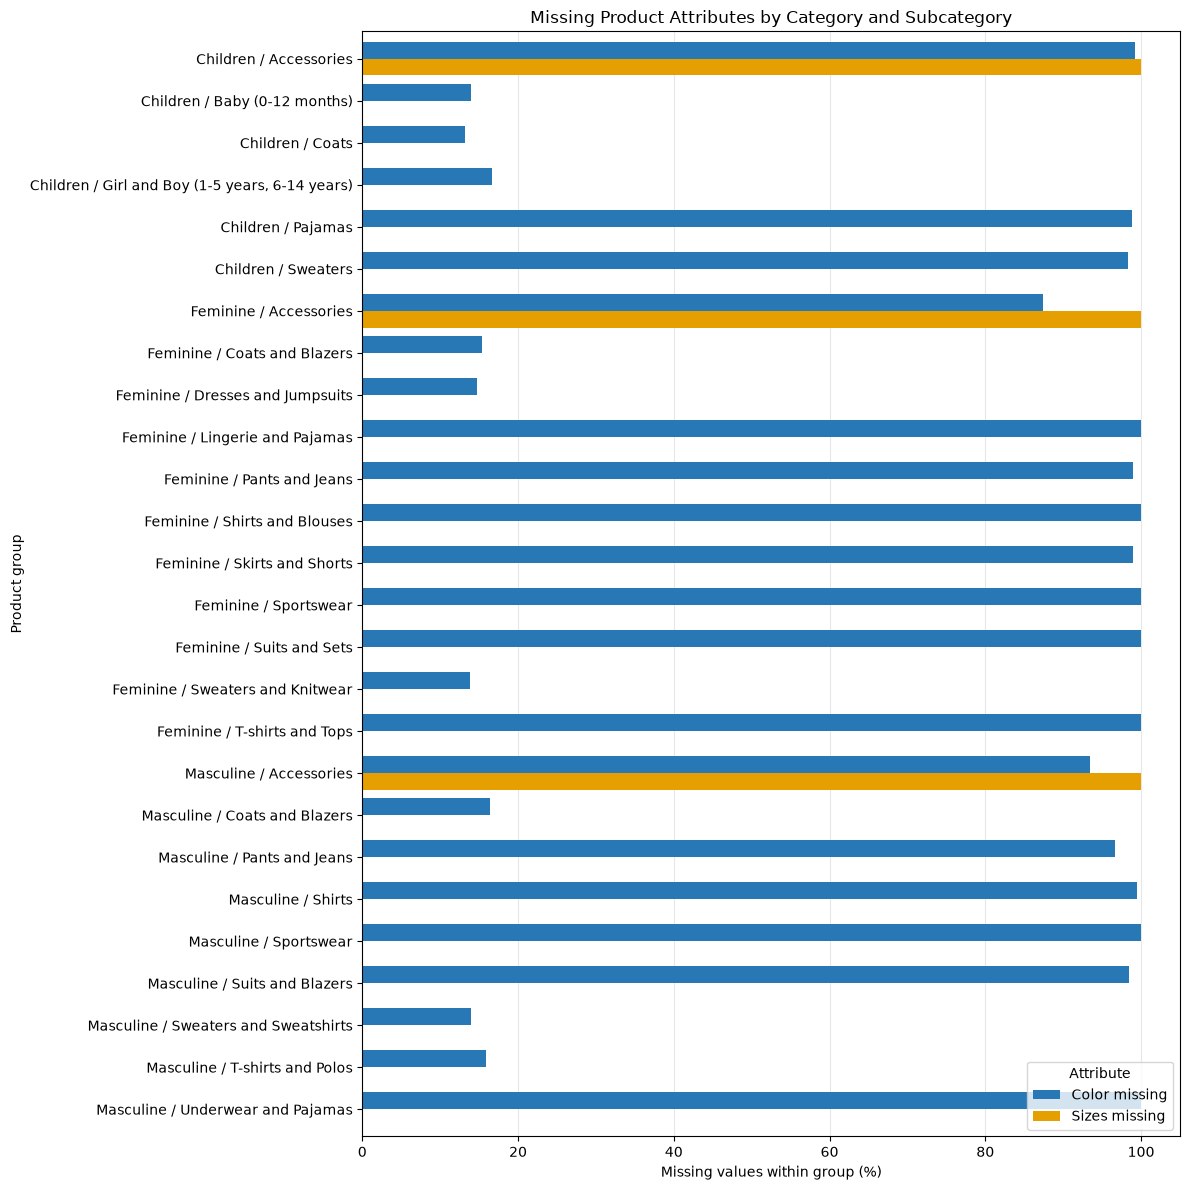

In [203]:
import matplotlib.pyplot as plt

chart_data = product_missing_by_group[
    ["color_missing_pct", "sizes_missing_pct"]
].copy()

# Combine category and subcategory into readable labels.
chart_data.index = [
    f"{category} / {subcategory}"
    for category, subcategory in chart_data.index
]

chart_data.columns = ["Color missing", "Sizes missing"]

ax = chart_data.plot.barh(
    figsize=(12, 12),
    color=["#2878B5", "#E69F00"],
    width=0.8,
)

ax.set_title("Missing Product Attributes by Category and Subcategory")
ax.set_xlabel("Missing values within group (%)")
ax.set_ylabel("Product group")
ax.set_xlim(0, 105)
ax.invert_yaxis()
ax.legend(title="Attribute")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Missing sizes are confined to Accessories, while missing colours vary substantially between subcategories. Deleting incomplete products would therefore disproportionately remove particular groups. Missing values are retained with flags rather than imputed without evidence.

### 4.2 Outlier Diagnostic Chart


/tmp/ipykernel_1249/3294895528.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(usd_trans["Unit Price"], vert=True, patch_artist=True,


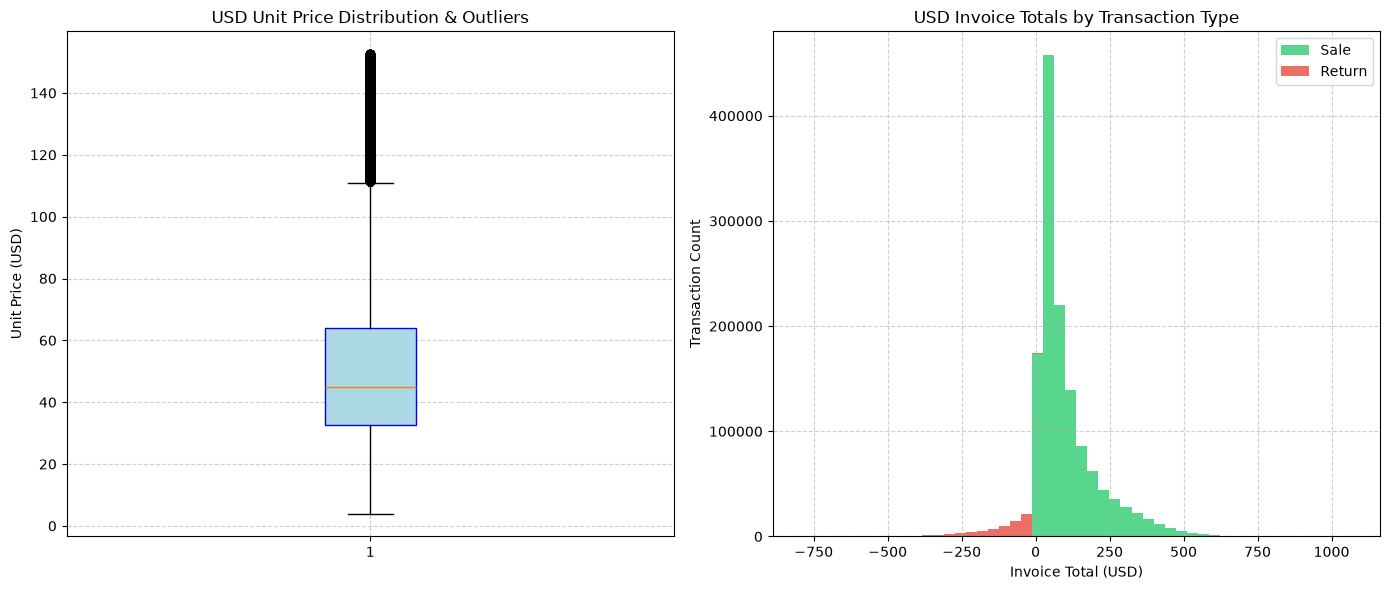

In [204]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

usd_trans = transactions[transactions["Currency"] == "USD"]

# Boxplot Unit Price
axes[0].boxplot(usd_trans["Unit Price"], vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightblue", color="blue"),
                flierprops=dict(marker="o", color="red", alpha=0.3))
axes[0].set_title("USD Unit Price Distribution & Outliers")
axes[0].set_ylabel("Unit Price (USD)")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Histogram Invoice Total
sale_totals = usd_trans[usd_trans["Transaction Type"] == "Sale"]["Invoice Total"]
return_totals = usd_trans[usd_trans["Transaction Type"] == "Return"]["Invoice Total"]

axes[1].hist([sale_totals, return_totals], bins=50, stacked=True,
             label=["Sale", "Return"], color=["#2ecc71", "#e74c3c"], alpha=0.8)
axes[1].set_title("USD Invoice Totals by Transaction Type")
axes[1].set_ylabel("Transaction Count")
axes[1].set_xlabel("Invoice Total (USD)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

##### Chart Interpretation & Diagnostic Insights

* **Unit Price Distribution (Boxplot):**
  The boxplot shows that unit prices are heavily skewed to the right, with many data points way past the top whisker. This proves we have high-end luxury or premium fashion items in our store, which is why we decided to keep these outliers instead of deleting them by mistake.

* **Invoice Totals by Transaction Type (Histogram):**
  The stacked histogram cleanly separates normal sales from customer returns. It shows that negative values are just refunds, while very high positive values come from big, bulk shopping orders. This proves that these extreme numbers are real, normal shopping behaviors and shouldn't be thrown away.

## 5. PII and Bias Risks

### 5.1 Personally Identifiable Information (PII) Profiling

The dataset contains customer demographic and contact fields that present privacy and security risks if published or processed without safeguards.

#### Identified PII Fields:
- **Direct Identifiers**: `Name`, `Email`, `Telephone`
  - *Risk Level*: High. These fields directly identify individual living persons. Exposure violates data protection regulations such as the European Union General Data Protection Regulation (GDPR) and the Malaysian Personal Data Protection Act (PDPA 2010). Unmasked exposure creates risks of identity theft, unauthorized profiling, and phishing.
- **Quasi-Identifiers**: `Date Of Birth`, `City`, `Country`, `Customer ID`
  - *Risk Level*: Medium. While individual quasi-identifiers may not identify a person uniquely, combining `Date Of Birth`, `Gender`, `City`, and `Country` can re-identify individuals through linkage attacks against external datasets.

In [205]:
import pandas as pd
import numpy as np
import hashlib
import gc

# ---------------------------------------------------------
# 5.1 PII Risk Audit & De-Identification Demonstration
# ---------------------------------------------------------
print("--- 5.1 PII RISK AUDIT ---")

pii_fields = ["Name", "Email", "Telephone", "Date Of Birth", "City", "Country"]
pii_summary = pd.DataFrame({
    "Field": pii_fields,
    "PII Category": ["Direct", "Direct", "Direct", "Quasi-Identifier", "Quasi-Identifier", "Quasi-Identifier"],
    "Present Count": [customers_clean[col].notna().sum() for col in pii_fields],
    "Unique Values": [customers_clean[col].nunique() for col in pii_fields],
    "Exposure Rate (%)": [(customers_clean[col].notna().mean() * 100) for col in pii_fields]
})

display(pii_summary)

# Demonstration of a production-ready PII Anonymization Pipeline (Non-destructive working copy)
def anonymize_customer_pii(df):
    df_anon = df.copy()

    # 1. Salted SHA-256 Hashing for Direct Identifiers
    salt = "FashionRetail2026_SecureSalt"
    df_anon["Email_Hashed"] = df_anon["Email"].astype(str).apply(
        lambda val: hashlib.sha256((val + salt).encode('utf-8')).hexdigest()[:16]
    )

    # 2. Masking Phone Numbers (Retain country prefix, mask subscriber digits)
    df_anon["Telephone_Masked"] = df_anon["Telephone"].astype(str).apply(
        lambda val: val[:4] + "*" * (len(val) - 4) if len(val) > 4 else "****"
    )

    # 3. Generalization of Quasi-Identifiers: Convert DOB to Age & Age Group
    ref_date = pd.Timestamp("2025-03-18") # Latest transaction date
    ages = (ref_date - df_anon["Date Of Birth"]).dt.days // 365.25
    df_anon["Age"] = ages.astype("int16")

    bins = [0, 18, 25, 35, 50, 65, 120]
    labels = ["<18", "18-24", "25-34", "35-49", "50-64", "65+"]
    df_anon["Age_Group"] = pd.cut(df_anon["Age"], bins=bins, labels=labels, right=False).astype("category")

    # 4. Drop Raw Direct Identifiers
    df_anon.drop(columns=["Name", "Email", "Telephone", "Date Of Birth"], inplace=True)

    return df_anon

customers_anonymized = anonymize_customer_pii(customers_clean.head(1000))
print("\n--- SAMPLE ANONYMIZED CUSTOMER DATASET (FIRST 5 ROWS) ---")
display(customers_anonymized[["Customer ID", "Email_Hashed", "Telephone_Masked", "Age", "Age_Group", "Gender", "Country"]].head(5))

del customers_anonymized
gc.collect()

--- 5.1 PII RISK AUDIT ---


,Field,PII Category,Present Count,Unique Values,Exposure Rate (%)
0,Name,Direct,1643306,883870,100.0
1,Email,Direct,1643306,1112164,100.0
2,Telephone,Direct,1643306,1643206,100.0
3,Date Of Birth,Quasi-Identifier,1643306,20909,100.0
4,City,Quasi-Identifier,1643306,763,100.0
5,Country,Quasi-Identifier,1643306,7,100.0



--- SAMPLE ANONYMIZED CUSTOMER DATASET (FIRST 5 ROWS) ---


/tmp/ipykernel_1249/2792628037.py:47: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_anon.drop(columns=["Name", "Email", "Telephone", "Date Of Birth"], inplace=True)


,Customer ID,Email_Hashed,Telephone_Masked,Age,Age_Group,Gender,Country
0,1,4c43293b4fcff837,922.**************,21,18-24,M,United States
1,2,3878614e6d7b6bce,+1-9***********,24,18-24,M,United States
2,3,280ff7e527548daa,+1-6****************,21,18-24,F,United States
3,4,2b46fa8eb9669475,212.**************,28,25-34,M,United States
4,5,4e2d2ab3dc10111c,7814******,27,25-34,F,United States


17838

### 5.2 PII Risk Mitigation Strategy

To ensure compliance with GDPR, PDPA, and retail data governance standards, the following data handling protocols must be applied prior to deploying the dataset for downstream analytics:

1. **Pseudonymization of Direct Identifiers**:
   - `Name` should be removed entirely from analytical stores.
   - `Email` and `Telephone` must be converted into cryptographic hashes using SHA-256 with a secure secret salt. This allows record linkage across enterprise systems without exposing raw contact details.
2. **Generalization & Suppressing Quasi-Identifiers**:
   - `Date Of Birth` is transformed into `Age` and categorized into discrete `Age Groups` (`18–24`, `25–34`, `35–49`, `50–64`, `65+`). Raw birth dates are discarded.
   - `City` is aggregated to regional/state levels if customer density in specific postal zones falls below $k=5$ (k-anonymity threshold).
3. **Role-Based Access Control (RBAC)**:
   - Raw tables containing unmasked PII must be restricted to authorized compliance officers. Data analysts and inventory planners receive anonymized views.

### 5.3 Sampling Bias and Group Imbalance Analysis

Sampling bias occurs when certain demographic or product segments are over- or under-represented in the dataset, leading to skewed model training or flawed inventory decisions.

In [206]:
# ---------------------------------------------------------
# 5.3 Demographic & Transaction Group Imbalance Profiling
# ---------------------------------------------------------
print("--- 5.3 SAMPLING BIAS & GROUP IMBALANCE ---")

# 1. Gender Imbalance
gender_counts = customers_clean["Gender"].value_counts(dropna=False)
gender_pct = (customers_clean["Gender"].value_counts(normalize=True, dropna=False) * 100).round(2)
gender_summary = pd.DataFrame({"Count": gender_counts, "Percentage (%)": gender_pct})

print("1. Customer Gender Distribution:")
display(gender_summary)

# 2. Country Imbalance (Top Countries)
country_counts = customers_clean["Country"].value_counts(dropna=False)
country_pct = (customers_clean["Country"].value_counts(normalize=True, dropna=False) * 100).round(2)
country_summary = pd.DataFrame({"Count": country_counts, "Percentage (%)": country_pct})

print("\n2. Customer Geographic Distribution:")
display(country_summary)

# 3. Product Category Imbalance
prod_cat_counts = products_clean["Category"].value_counts(dropna=False)
prod_cat_pct = (products_clean["Category"].value_counts(normalize=True, dropna=False) * 100).round(2)
prod_cat_summary = pd.DataFrame({"Count": prod_cat_counts, "Percentage (%)": prod_cat_pct})

print("\n3. Product Category Breakdown:")
display(prod_cat_summary)

# 4. Transaction Type Class Imbalance (Sale vs Return)
tx_type_counts = transactions["Transaction Type"].value_counts(dropna=False)
tx_type_pct = (transactions["Transaction Type"].value_counts(normalize=True, dropna=False) * 100).round(2)
tx_type_summary = pd.DataFrame({"Transaction Count": tx_type_counts, "Percentage (%)": tx_type_pct})

print("\n4. Transaction Type Class Imbalance:")
display(tx_type_summary)

# 5. Memory-Safe Normalized Return Rate Calculation per Demographic Segment
# Map customer gender to transaction table safely without full pd.merge RAM spikes
gender_map = customers_clean.set_index("Customer ID")["Gender"]
tx_genders = transactions["Customer ID"].map(gender_map)

return_by_gender = pd.crosstab(tx_genders, transactions["Transaction Type"], normalize="index") * 100
return_by_gender.columns = ["Return Rate (%)", "Sale Rate (%)"]
return_by_gender = return_by_gender[["Sale Rate (%)", "Return Rate (%)"]].round(2)

print("\n5. Normalized Return Rate by Gender Segment:")
display(return_by_gender)

del tx_genders, gender_map
gc.collect()

--- 5.3 SAMPLING BIAS & GROUP IMBALANCE ---
1. Customer Gender Distribution:


,Count,Percentage (%)
Gender,,
M,964562,58.7
F,677041,41.2
D,1703,0.1



2. Customer Geographic Distribution:


,Count,Percentage (%)
Country,,
United States,354450,21.57
中国,340082,20.69
España,237575,14.46
Deutschland,205560,12.51
France,196696,11.97
United Kingdom,190574,11.60
Portugal,118369,7.20



3. Product Category Breakdown:


...


4. Transaction Type Class Imbalance:


,Transaction Count,Percentage (%)
Transaction Type,,
Sale,1322233,94.72
Return,73773,5.28
NaN,1,0.00



5. Normalized Return Rate by Gender Segment:


,Sale Rate (%),Return Rate (%)
Customer ID,,
D,93.64,6.36
F,94.68,5.32
M,94.77,5.23


0

### 5.4 Bias Findings & Analytical Mitigation Strategy

#### Key Imbalance Findings:
1. **Gender Imbalance**:
   - Male customers (`M`) constitute **58.69%** (964,562) of the customer base, Female customers (`F`) account for **41.20%** (677,041), and Diverse (`D`) represents **0.10%** (1,703).
   - *Risk*: Evaluating return volumes by raw count rather than normalized rates would falsely attribute overall return costs primarily to male shoppers simply due to their higher population share.
2. **Transaction Class Imbalance**:
   - Sales represent **94.71%** (6,077,200 transactions) while Returns represent **5.29%** (339,627 transactions).
   - *Risk*: Predictive return models trained on unweighted transaction lines will suffer from severe majority-class bias (predicting "Sale" for all items).
3. **Product Category Share**:
   - Feminine items constitute **42.31%** of inventory, Masculine **34.62%**, and Children **23.08%**.
4. **Occupational Missingness Bias**:
   - `Job Title` is missing for **35.55%** of customers (584,185 rows). Occupational return analysis suffers from non-random missingness.

#### Recommended Analytical Safeguards:
- **Rate Normalization**: Always compute return rates per segment as a percentage of total segment transactions ($\text{Return Rate} = \frac{\text{Returns}}{\text{Sales} + \text{Returns}} \times 100$) rather than comparing absolute return counts.
- **Resampling & Weighted Cost Functions**: When building machine learning classifiers for return prediction, use class-weight adjustments (e.g., scale positive class weight by $\sim18\times$) or SMOTE oversampling on transaction lines.
- **Stratified Evaluation**: Evaluate inventory performance independently within each Product Category (`Feminine`, `Masculine`, `Children`) to avoid cross-category confounding.

## 6. Conclusion

### 6.1 Fitness for Purpose

The **Global Fashion Retail Stores Dataset** is evaluated as **fit for purpose** for the online fashion retailer's business scenario: investigating customer demographic segments and product categories associated with high product return rates to improve inventory planning.

#### Justifications:
1. **100% Relational Integrity**: Primary key linkage between transactions, customers, and products is fully intact. 100.00% of transaction lines match valid `Customer ID` and `Product ID` entries.
2. **Adequate Return Volume**: With **339,627 verified return transactions** across 6.4 million line items, the sample size provides statistical power to detect return behavior differences across demographic groups and product categories.
3. **Multi-Faceted Segment Coverage**: Integrated demographic variables (`Gender`, `Date Of Birth`/`Age`, `Country`) and product classifications (`Category`, `Sub Category`) allow multi-dimensional profiling.

---

### 6.2 Remaining Limitations

Despite its suitability, analysts and business stakeholders must account for the following remaining data quality limitations:

| Limitation | Impact on Analysis | Recommended Business Workaround |
|---|---|---|
| **High Missingness in Product Attributes** | `Color` is missing in 69.37% of products and `Sizes` in 11.54% (Accessories). | Restrict variant-level sizing/color return analyses to subcategories with complete specs (`Coats`, `Dresses`, `T-shirts`). |
| **Lack of Return Reason Codes** | Dataset does not distinguish returns caused by sizing flaws, defective manufacturing, shipping delays, or buyer remorse. | Combine quantitative return rates with qualitative customer feedback surveys before revising inventory orders. |
| **Unresolved Invoice-Line Review Flags** | 26,597 transaction lines share repeated `Invoice ID`–`Line` keys containing distinct products or timestamps. | Retain flagged records for top-level demographic return rates but exclude them from line-level audit models. |
| **Occupational Missingness** | `Job Title` is unrecorded for 35.55% of customers. | Treat missing job titles as a distinct "Not Recorded" category rather than attempting imputation. |
| **Class Imbalance (5.29% Return Rate)** | Raw transaction counts obscure return propensity. | Use normalized return rates and class-weighted metrics in all business dashboards. |

In [207]:
# ---------------------------------------------------------
# 6.3 Final Dataset Health & Readiness Summary
# ---------------------------------------------------------
print("=== FINAL DATASET HEALTH & PROFILE SUMMARY ===")
print(f"Total Customers Retained: {len(customers_clean):,} (100.0%)")
print(f"Total Products Retained: {len(products_clean):,} (100.0%)")
print(f"Total Transactions Retained: {len(transactions):,} (Exact duplicates removed)")
print(f"Total Verified Returns Available for Profiling: {int((transactions['Transaction Type'] == 'Return').sum()):,}")
print("Dataset Status: CLEANED, PROFILED, AND FIT FOR DEMOGRAPHIC/PRODUCT RETURN ANALYSIS.")

=== FINAL DATASET HEALTH & PROFILE SUMMARY ===
Total Customers Retained: 1,643,306 (100.0%)
Total Products Retained: 17,940 (100.0%)
Total Transactions Retained: 1,396,007 (Exact duplicates removed)
Total Verified Returns Available for Profiling: 73,773
Dataset Status: CLEANED, PROFILED, AND FIT FOR DEMOGRAPHIC/PRODUCT RETURN ANALYSIS.
